In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib as mpl
import xml.etree.ElementTree as ET
import shapely
import cartopy
import pyproj
import numpy
from math import sin,cos,radians
from pathlib import Path
from datetime import datetime

In [2]:
title = "Seduisant WNR Series 2 5/14/2026"
outfileBase = "Seduisant WNR Series 2 2026-05-14"
outputPath = "./output/Seduisant"

#every time i review a track i find a mark is off course
waypointFile = "./tracks/Pontchartrain Waypoints_2026-05-14.gpx"
trackFile = "./tracks/Track_2026-05-13 204159.gpx"
windFile = "./windData/burl1_2026-05-14.pickle"
proj = cartopy.crs.Mercator()
buffer = 0.25 / 60 #buffer in nautical miles
nm2Meter = 1852.0

In [3]:
wgs84 = pyproj.crs.CRS.from_string('WGS84')
utm = pyproj.crs.CRS.from_string('EPSG:32615')

In [4]:
Path(outputPath).mkdir(exist_ok=True,parents=True)

In [5]:
waypointXML = ET.parse(waypointFile)

In [6]:
wptList = []
for child in waypointXML.getroot().findall('{http://www.topografix.com/GPX/1/1}wpt'):
    data = {
                'name':child.find('{http://www.topografix.com/GPX/1/1}name').text,
                'geometry':shapely.Point(child.attrib['lon'],child.attrib['lat'])
    }
    
    
    wptList.append(data)

waypointGdf = gpd.GeoDataFrame(data= pd.DataFrame.from_dict(wptList), geometry='geometry', crs=wgs84)

In [7]:
waypointGdf.drop_duplicates(subset=['name'], inplace=True)

In [8]:
waypointGdf['name'] = waypointGdf['name'].str.replace('"','').str.replace('SYC ','')

In [9]:
waypointGdf.set_index('name', inplace=True)

In [10]:
#map is two busy filter out points that dont matter
waypointGdf = waypointGdf[waypointGdf.index.isin(['C','G','A'])].copy()

In [11]:
trkXML = ET.parse(trackFile)

In [12]:
trkSegXML = trkXML.getroot().find('{http://www.topografix.com/GPX/1/1}trk').\
    find('{http://www.topografix.com/GPX/1/1}trkseg')

In [13]:
trkList = []
for child in trkSegXML:
    data = {
                'time':child.find('{http://www.topografix.com/GPX/1/1}time').text,
                'geometry':shapely.Point(child.attrib['lon'],child.attrib['lat'])
           }
    
    trkList.append(data)

trkGdf = gpd.GeoDataFrame(data=pd.DataFrame.from_dict(trkList), geometry='geometry', crs=wgs84)

In [14]:
trkGdf['time'] = pd.to_datetime( trkGdf['time'] ).dt.tz_convert('US/Central')
print(f"Start time {trkGdf['time'].min()}")

Start time 2026-05-13 17:47:38-05:00


In [15]:
trkGdf['timeDelta'] = trkGdf['time'] - trkGdf['time'].shift(1)
trkGdf['timeCumsum'] = trkGdf['timeDelta'].cumsum()
print(f"Mean time between measure {trkGdf['timeDelta'].mean()}")

Mean time between measure 0 days 00:00:08.159906


In [16]:
geod = pyproj.Geod(ellps='clrk66')
print(f"Total distance {geod.line_length(trkGdf['geometry'].x, trkGdf['geometry'].y) / nm2Meter}nm")

Total distance 8.578479460039519nm


In [17]:
trkGdf['bearing'] = geod.inv(trkGdf['geometry'].x,trkGdf['geometry'].y, trkGdf['geometry'].shift(1).x, trkGdf['geometry'].shift(1).y)[1]

In [18]:
mask = trkGdf['bearing'] < 0
trkGdf.loc[mask, 'bearing'] = trkGdf['bearing'][mask] + 360.0

In [19]:
trkGdf['delta_distance'] = numpy.nan
trkGdf.loc[1:,'delta_distance'] = geod.line_lengths(trkGdf['geometry'].x, trkGdf['geometry'].y) / nm2Meter

In [20]:
trkGdf['dist_cumsum'] = trkGdf['delta_distance'].cumsum()

In [21]:
trkGdf['delta_distance'].sum()

np.float64(8.578479460039523)

In [22]:
trkGdf['speed'] = (60.0 * 60.0 * trkGdf['delta_distance']) / trkGdf['timeDelta'].dt.total_seconds()

In [23]:
print(f"speed max:{trkGdf['speed'].max()}\tmin:{trkGdf['speed'].min()}\tmean:{trkGdf['speed'].mean()}")

speed max:7.236660747584934	min:0.017120524587162164	mean:3.6006955378652266


In [24]:
trkGdf.set_index('time',inplace=True)

In [25]:
trkGdf = trkGdf[numpy.logical_and( trkGdf.index>'2026-05-13 19:10:00-05:00',\
                                   trkGdf.index<'2026-05-13 19:55:00-05:00')].copy()

In [26]:
trkGdf.head()

,geometry,timeDelta,timeCumsum,bearing,delta_distance,dist_cumsum,speed
time,,,,,,,
2026-05-13 19:10:01-05:00,POINT (-90.10332 30.03312),0 days 00:00:02,0 days 01:22:23,246.600434,0.001541,3.509758,2.774087
2026-05-13 19:10:10-05:00,POINT (-90.10346 30.03298),0 days 00:00:09,0 days 01:22:32,222.313820,0.011011,3.520770,4.404453
2026-05-13 19:10:17-05:00,POINT (-90.10359 30.0329),0 days 00:00:07,0 days 01:22:39,232.449424,0.008149,3.528919,4.191084
2026-05-13 19:10:21-05:00,POINT (-90.10366 30.03285),0 days 00:00:04,0 days 01:22:43,232.708167,0.005059,3.533978,4.553378
2026-05-13 19:10:29-05:00,POINT (-90.10379 30.03275),0 days 00:00:08,0 days 01:22:51,227.656551,0.009273,3.543251,4.172826


In [27]:
windDf = pd.read_pickle(windFile)
mask = numpy.logical_and( (windDf.index >= trkGdf.index.min()),\
                        windDf.index <= trkGdf.index.max())
windDf = windDf[mask].copy()
medianWind = windDf['WDIR'].median()
meanWindSpeed = windDf['WSPD'].mean()
print(f"Median wind direction: {medianWind}")
print(f"Mean wind speed:  {meanWindSpeed}")
windDf.head()

Median wind direction: 266.5
Mean wind speed:  3.475


,#YY,MM,DD,hh,mm,WDIR,WSPD,GDR,GST,GTIME
2026-05-13 19:50:00-05:00,2026,5,14,0,50,262,3.1,999,99.0,9999
2026-05-13 19:40:00-05:00,2026,5,14,0,40,264,3.1,999,99.0,9999
2026-05-13 19:30:00-05:00,2026,5,14,0,30,269,4.1,999,99.0,9999
2026-05-13 19:20:00-05:00,2026,5,14,0,20,270,3.6,999,99.0,9999


In [28]:
def createWindQuiver(ax):
    
    arrowRows = 20
    axExtent = ax.get_extent()
    lonMin = axExtent[0]
    lonMax = axExtent[1]
    lonRange = numpy.arange(lonMin,lonMax, (lonMax-lonMin)/arrowRows)
    latMin = axExtent[2]
    latMax = axExtent[3]
    latRange = numpy.arange(latMin,latMax, (latMax-latMin)/arrowRows)
    
    (lonMesh,latMesh) = numpy.meshgrid(lonRange, latRange)
    ax.quiver(x=lonMesh,y=latMesh,\
              u=sin(radians(medianWind+180)),v=cos(radians(medianWind+180)),\
              angles='uv',\
              color =(0,0,0,0.2),
              zorder=-2,
              label=f"Wind Dir {medianWind:.0f}\U000000B0")


In [29]:
def createPlot(ax, extent, s=72, wpS=500,plotWind=True, lblWpt=True ,extentBuffer=buffer, df=trkGdf,colorMap=mpl.cm.magma):
    
    boundBox = shapely.geometry.box(*extent)
    #wptMask = waypointGdf['geometry'].map(lambda pt: boundBox.contains(pt))
    
    tmDelta = pd.Timedelta('1 minute')
    for tm in dirArrowTimes:
        pt1 = df['geometry'].asof(tm)
        pt2 = df['geometry'].asof(tm+tmDelta)
        arrowBuffer = 0.001
        arrow = mpl.patches.FancyArrowPatch( (pt1.x-arrowBuffer, pt1.y+arrowBuffer), (pt2.x-arrowBuffer, pt2.y+arrowBuffer) ,mutation_scale=20, zorder=-1      )
        ax.add_patch(arrow)
    
    
    ax.scatter(waypointGdf.geometry.x, waypointGdf.geometry.y, marker='s',s=wpS, c='r', label='Marker')

    if lblWpt:
        for idx,item in waypointGdf.iterrows():
            ax.text(item['geometry'].x,item['geometry'].y,idx, va='center', ha='center', fontsize='20', fontname='serif',c='b' )
    
    ax.set_xlim(extent[0]-extentBuffer, extent[2]+extentBuffer)
    ax.set_ylim(extent[1]-extentBuffer, extent[3]+extentBuffer)
    ax.coastlines()
    
    
    trkPlt = ax.scatter(df.geometry.x,df.geometry.y, c=colorMap(norm(df['speed'])), s=s,zorder=5)
    
    if plotWind:
        createWindQuiver(ax)




In [30]:
dirArrowTimes = pd.date_range(start=trkGdf.index[0], end=trkGdf.index[-1], periods=11)[1:]

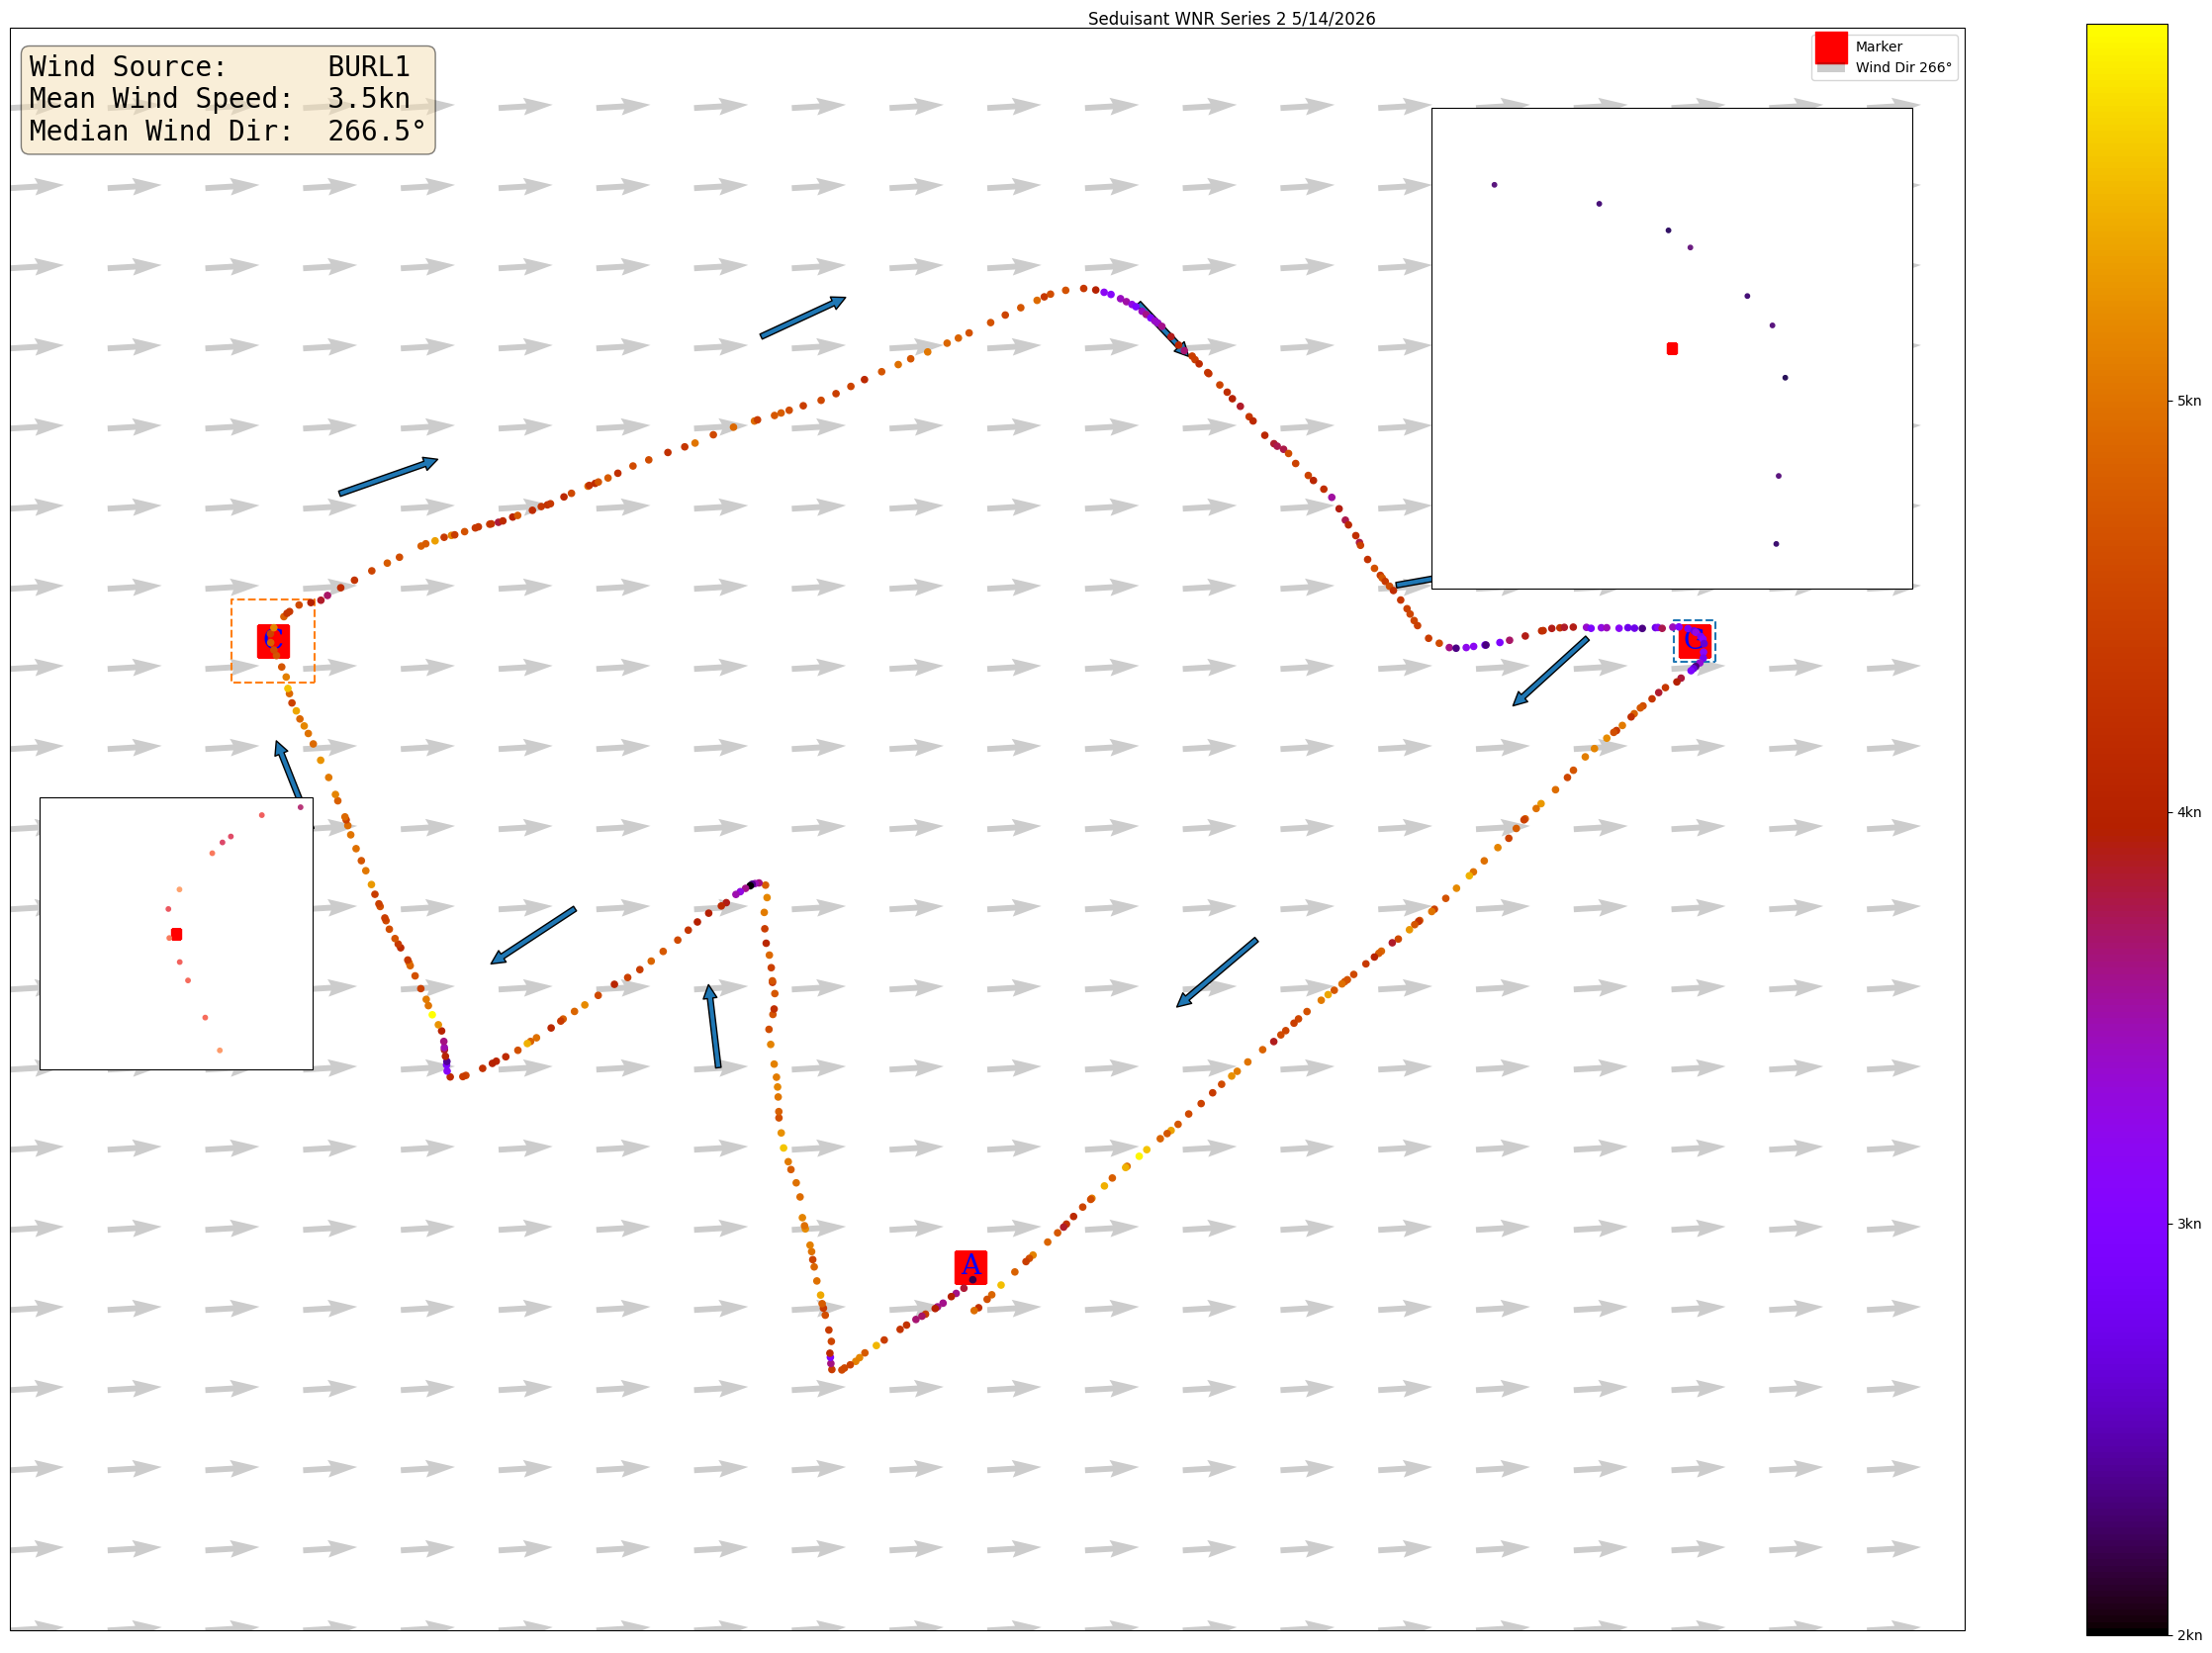

In [31]:
figsize = (25,17)
fig,ax = plt.subplots(1, figsize=figsize ,subplot_kw={'projection': proj})

norm = mpl.colors.Normalize(vmin=trkGdf['speed'].min(), vmax = trkGdf['speed'].max(), clip=True)
colorbarTicks = numpy.arange(norm.vmin,norm.vmax+0.001,1.0)
colorMap = mpl.cm.gnuplot
cax = fig.colorbar( plt.cm.ScalarMappable(norm=norm, cmap=colorMap), ax=ax)   
cax.set_ticks(colorbarTicks)
cax.set_ticklabels( [f"{int(i)}kn" for i in colorbarTicks])

createPlot(ax,s=20, extent=trkGdf.total_bounds,colorMap=colorMap)


wptRadius = 0.02 / 60
gExtent = waypointGdf.loc['G','geometry'].buffer(wptRadius).bounds
gBox = shapely.geometry.box(*gExtent)
ax.plot(gBox.exterior.xy[0],gBox.exterior.xy[1],zorder=4,linestyle='--')
gInset = ax.inset_axes([0.7,0.65,0.3,0.3], projection=proj, zorder=10 )
createPlot(gInset, gExtent, s=10, wpS=50, plotWind=False, lblWpt=False, extentBuffer=0 )

wptRadius = 0.04 / 60
cExtent = waypointGdf.loc['C','geometry'].buffer(wptRadius).bounds
cBox = shapely.geometry.box(*cExtent)
ax.plot(cBox.exterior.xy[0],cBox.exterior.xy[1],zorder=4,linestyle='--')
cInset = ax.inset_axes([0,0.35,0.17,0.17], projection=proj, zorder=10 )
createPlot(cInset, cExtent, s=10, wpS=50, plotWind=False, lblWpt=False, extentBuffer=0 )

#reqExtent = trkGdf[reqMask].total_bounds
#reqBox = shapely.geometry.box(*reqExtent)   
#ax.plot(reqBox.exterior.xy[0],reqBox.exterior.xy[1],zorder=4,linestyle='--')
#reqInset = ax.inset_axes([0.01,0.68,0.3,0.3], projection=proj, zorder=3 )
#createPlot(reqInset, reqExtent, s=10, wpS=50, plotWind=False, lblWpt=False, extentBuffer=0 )


#add wind speed
windStr = f"""Wind Source:      BURL1
Mean Wind Speed:  {meanWindSpeed:.1f}kn
Median Wind Dir:  {medianWind}\U000000B0"""
ax.text(0.01,0.93,windStr, transform=ax.transAxes,\
        fontsize=20,\
        fontfamily='monospace',\
       bbox={
           'boxstyle':'round',
           'facecolor':'wheat',
           'alpha':0.5
       })

ax.legend()

fig.suptitle(title)
fig.tight_layout()
fig.savefig(f"{outputPath}/{outfileBase}.jpg")
fig.savefig(f"{outputPath}/{outfileBase}.svg")

In [32]:
reqMask = numpy.logical_and( trkGdf.index>'2026-05-13 19:27:00-05:00',\
                             trkGdf.index<'2026-05-13 19:33:00-05:00')

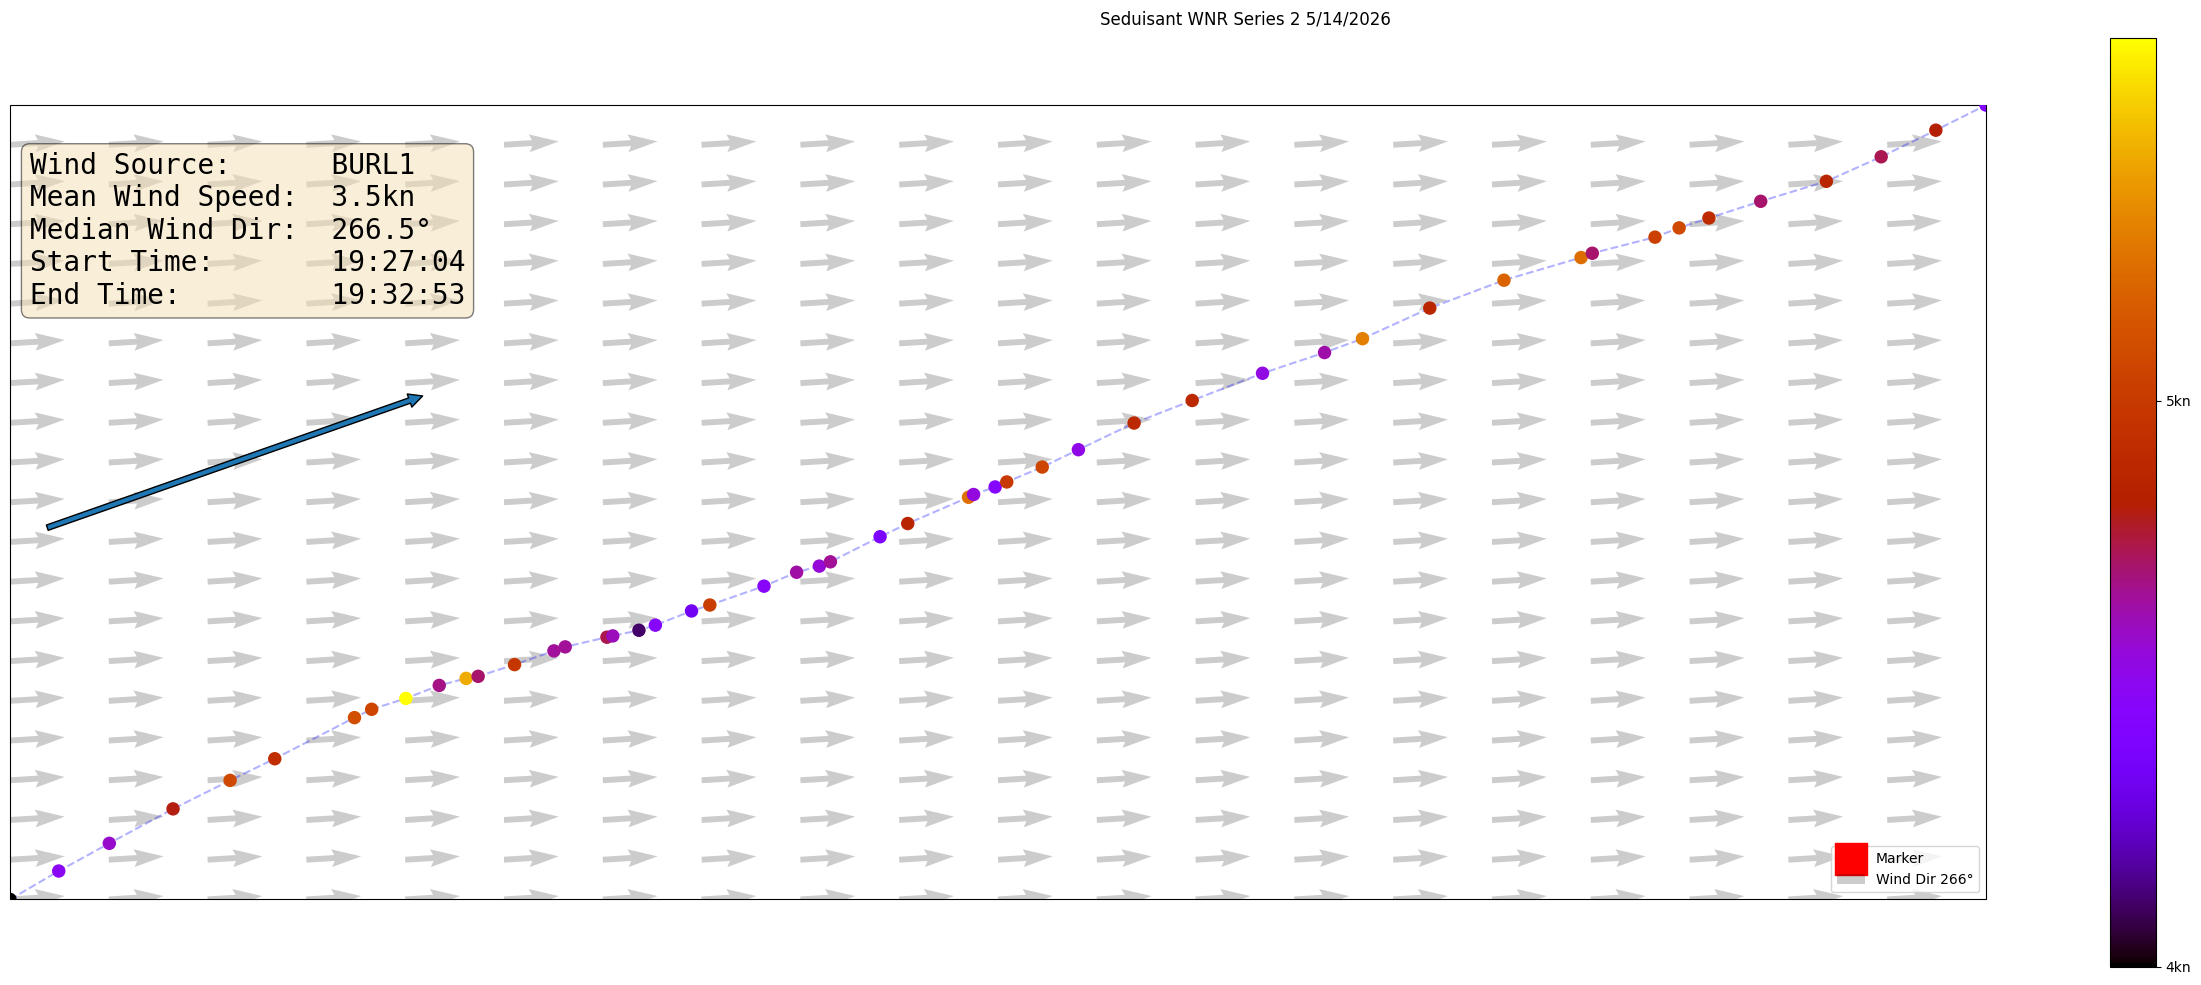

In [33]:
#crew member request subset

figsize = (25,10)
fig,ax = plt.subplots(1, figsize=figsize ,subplot_kw={'projection': proj})

norm = mpl.colors.Normalize(vmin=trkGdf['speed'][reqMask].min(), vmax = trkGdf['speed'][reqMask].max(), clip=True)
colorbarTicks = numpy.arange(norm.vmin,norm.vmax+0.001,1.0)
colorMap = mpl.cm.gnuplot
cax = fig.colorbar( plt.cm.ScalarMappable(norm=norm,cmap=colorMap), ax=ax)   
cax.set_ticks(colorbarTicks)
cax.set_ticklabels( [f"{int(i)}kn" for i in colorbarTicks])

createPlot(ax,s=75, extent=trkGdf[reqMask].total_bounds,colorMap=colorMap, extentBuffer=0, lblWpt=False)

#add wind speed
windStr = f"""Wind Source:      BURL1
Mean Wind Speed:  {meanWindSpeed:.1f}kn
Median Wind Dir:  {medianWind}\U000000B0
Start Time:       {trkGdf[reqMask].index[0].strftime('%H:%M:%S')}
End Time:         {trkGdf[reqMask].index[-1].strftime('%H:%M:%S')}"""
ax.text(0.01,0.75,windStr, transform=ax.transAxes,\
        fontsize=20,\
        fontfamily='monospace',\
       bbox={
           'boxstyle':'round',
           'facecolor':'wheat',
           'alpha':0.5
       })


ax.plot(trkGdf[reqMask].geometry.x,trkGdf[reqMask].geometry.y, c=(0,0,1,0.3), linestyle='--', zorder=4)

ax.legend()

fig.suptitle(title)
fig.tight_layout()
fig.savefig(f"{outputPath}/{outfileBase}_CrewReq.jpg")
fig.savefig(f"{outputPath}/{outfileBase}_CrewReq.svg")

In [34]:
print(datetime.now())

2026-05-18 11:13:51.330330
